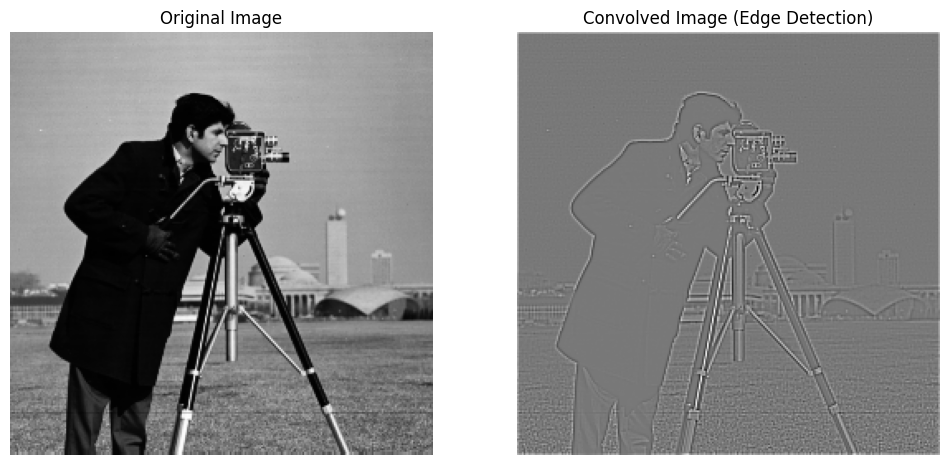

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def convolve_2d(image, kernel):
    """
    Perform 2D convolution without using built-in functions.

    Args:
        image (numpy.ndarray): Input grayscale image.
        kernel (numpy.ndarray): 2D filter (kernel).

    Returns:
        numpy.ndarray: Convolved output image.
    """
    # Get dimensions
    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    # Calculate output dimensions
    output_height = image_height - kernel_height + 1
    output_width = image_width - kernel_width + 1
    print( "Output size:", output_height, output_width)

    # Compute padding sizes
    pad_h = kernel_height // 2
    pad_w = kernel_width // 2
    print("padding required", pad_h, pad_w)

    # Pad the image with zeros (to maintain output size)
    padded_image = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)

    # Initialize output array
    output = np.zeros((image_height, image_width))

    # Perform convolution operation
    for i in range(image_height):
        for j in range(image_width):
            # Extract region of interest
            region = padded_image[i:i+kernel_height, j:j+kernel_width]
            # Element-wise multiplication and summation
            output[i, j] = np.sum(region * kernel)

    return output

# Load the grayscale image (Replace 'your_image.jpg' with your actual image file)
image = cv2.imread('/content/camraman.png', cv2.IMREAD_GRAYSCALE)

# sample 3x3 filter (e.g., edge detection)
kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

# Apply convolution
convolved_image = convolve_2d(image, kernel)

# Display the original and convolved images
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(image, cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(convolved_image, cmap='gray')
axes[1].set_title("Convolved Image (Edge Detection)")
axes[1].axis("off")

plt.show()


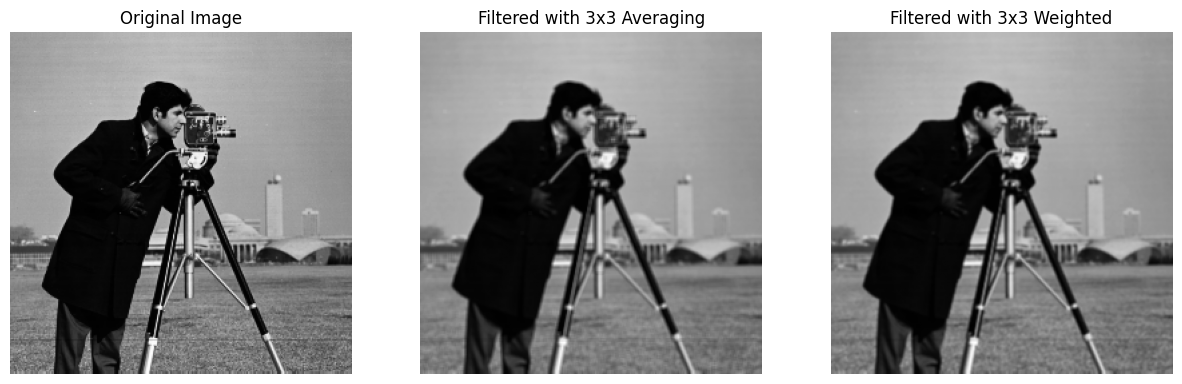

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve

# Load the image
image = cv2.imread('/content/camraman.png', cv2.IMREAD_GRAYSCALE)

# Define the first averaging filter (3x3)
filter_1 = (1/9) * np.array([
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
])

# Define the second weighted filter (3x3)
filter_2 = (1/16) * np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
])

# Apply convolution with the filters
filtered_image_1 = convolve(image, filter_1)
filtered_image_2 = convolve(image, filter_2)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(filtered_image_1, cmap='gray')
axes[1].set_title("Filtered with 3x3 Averaging")
axes[1].axis("off")

axes[2].imshow(filtered_image_2, cmap='gray')
axes[2].set_title("Filtered with 3x3 Weighted")
axes[2].axis("off")

plt.show()


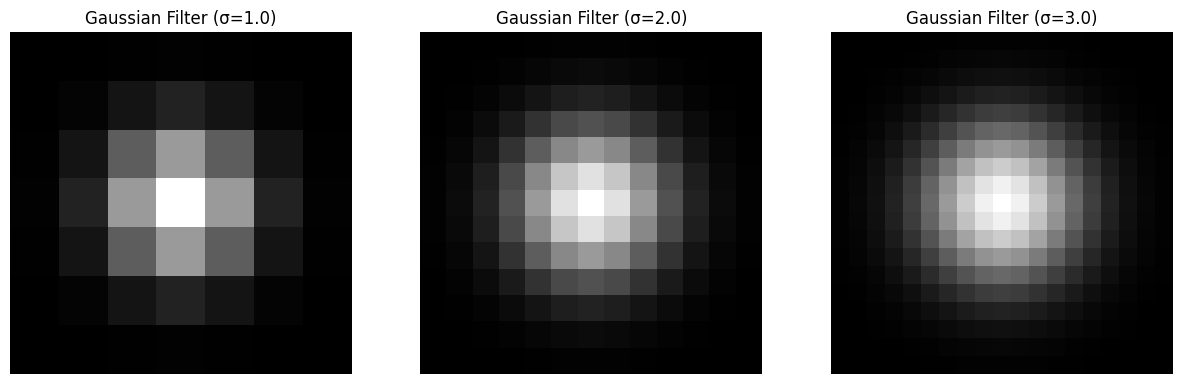

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def gaussian_filter(sigma):
    """
    Create a 2D Gaussian filter using the given formula.

    Args:
        sigma (float): Standard deviation of the Gaussian distribution.

    Returns:
        numpy.ndarray: The Gaussian filter.
    """
    # Define the filter size (d = 2 * π * σ, rounded to nearest odd integer)
    size = int(np.ceil(2 * np.pi * sigma))
    if size % 2 == 0:
        size += 1  # Ensure odd size for proper centering

    # Create a coordinate grid
    k = size // 2  # Half-size of the kernel
    x, y = np.meshgrid(np.arange(-k, k + 1), np.arange(-k, k + 1))

    # Compute the Gaussian function
    gaussian = (1 / (2 * np.pi * sigma**2)) * np.exp(-(x**2 + y**2) / (2 * sigma**2))

    # Normalize to range 0-255 for visualization
    gaussian_normalized = (gaussian - gaussian.min()) / (gaussian.max() - gaussian.min()) * 255
    gaussian_uint8 = gaussian_normalized.astype(np.uint8)

    return gaussian_uint8

# Generate Gaussian filters for three different sigma values
sigma_values = [1.0, 2.0, 3.0]
filters = [gaussian_filter(sigma) for sigma in sigma_values]

# Plot the Gaussian filters
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, sigma in enumerate(sigma_values):
    axes[i].imshow(filters[i], cmap='gray')
    axes[i].set_title(f'Gaussian Filter (σ={sigma})')
    axes[i].axis("off")

plt.show()


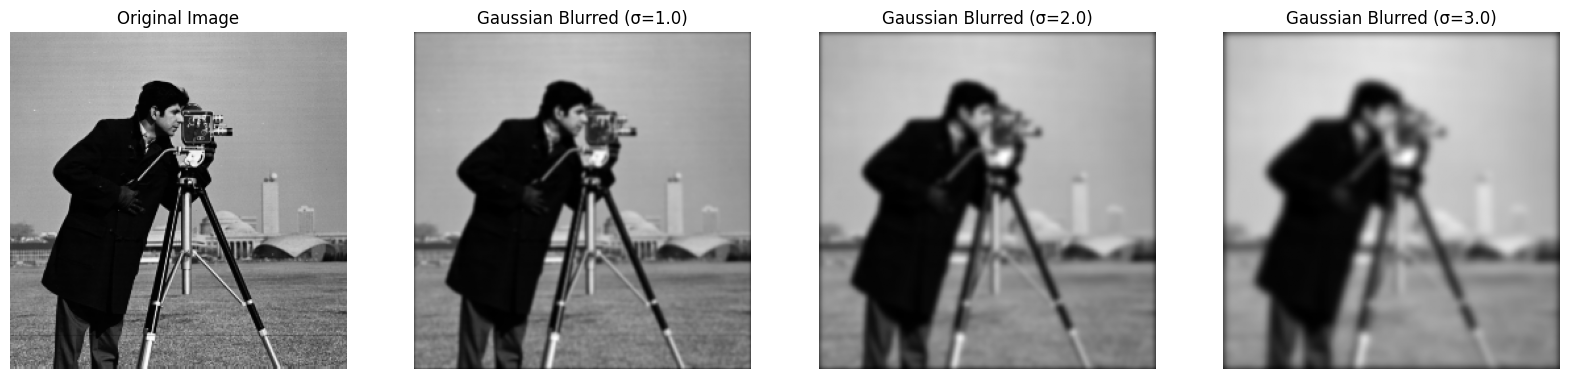

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def convolve_2d(image, kernel):
    """
    Perform 2D convolution without using built-in functions.

    Args:
        image (numpy.ndarray): Input grayscale image.
        kernel (numpy.ndarray): 2D filter (kernel).

    Returns:
        numpy.ndarray: Convolved output image.
    """
    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    # Compute padding sizes
    pad_h = kernel_height // 2
    pad_w = kernel_width // 2

    # Pad the image with zeros
    padded_image = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)

    # Initialize output array
    output = np.zeros((image_height, image_width))

    # Perform convolution
    for i in range(image_height):
        for j in range(image_width):
            region = padded_image[i:i+kernel_height, j:j+kernel_width]
            output[i, j] = np.sum(region * kernel)

    return output

def gaussian_filter(sigma):
    """
    Create a 2D Gaussian filter.

    Args:
        sigma (float): Standard deviation of the Gaussian function.

    Returns:
        numpy.ndarray: The Gaussian filter.
    """
    size = int(np.ceil(2 * np.pi * sigma))
    if size % 2 == 0:
        size += 1  # Ensure odd size

    k = size // 2
    x, y = np.meshgrid(np.arange(-k, k + 1), np.arange(-k, k + 1))

    # Compute the Gaussian function
    gaussian = (1 / (2 * np.pi * sigma**2)) * np.exp(-(x**2 + y**2) / (2 * sigma**2))

    # Normalize so the sum of all values is 1
    gaussian /= gaussian.sum()

    return gaussian

# Load the grayscale image
image_path = "/content/camraman.png"
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Apply Gaussian filter convolution with different sigma values
sigma_values = [1.0, 2.0, 3.0]  # Different sigma values for comparison
blurred_images = [convolve_2d(image, gaussian_filter(sigma)) for sigma in sigma_values]

# Display the original and blurred images
fig, axes = plt.subplots(1, 4, figsize=(20, 6))

# Show original image
axes[0].imshow(image, cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis("off")

# Show blurred images for different sigma values
for i, sigma in enumerate(sigma_values):
    axes[i + 1].imshow(blurred_images[i], cmap='gray')
    axes[i + 1].set_title(f"Gaussian Blurred (σ={sigma})")
    axes[i + 1].axis("off")

plt.show()


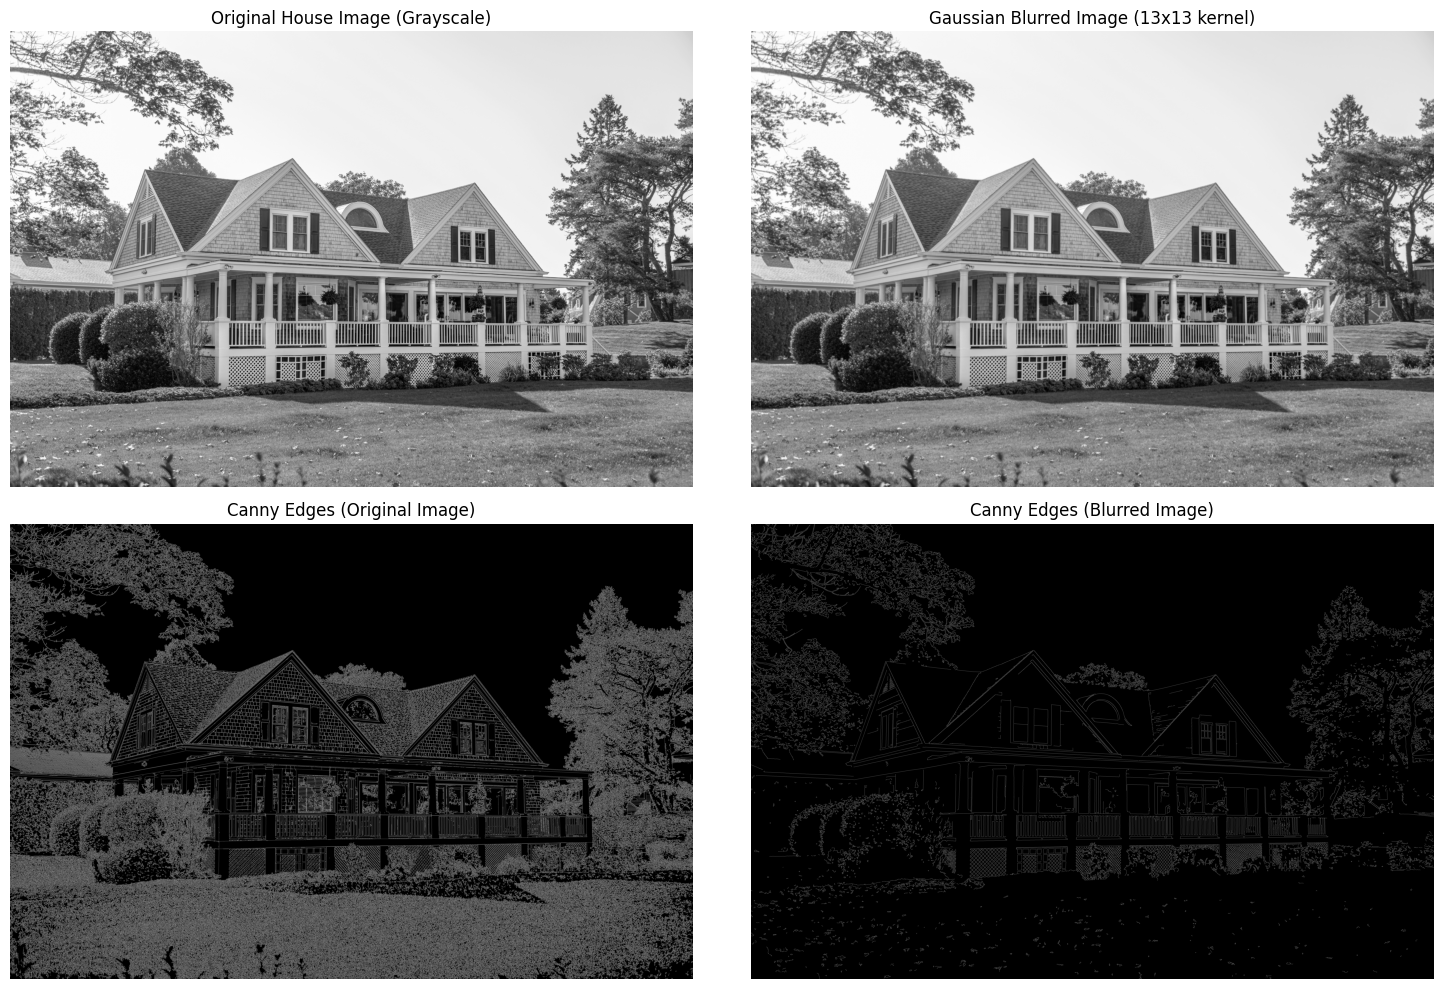

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the house image
house_image = cv2.imread("/content/house.jpg")
if house_image is None:
    raise ValueError("House image not found. Please check the file path.")

# Convert to RGB for display
house_rgb = cv2.cvtColor(house_image, cv2.COLOR_BGR2RGB)

# Convert to grayscale for processing
house_gray = cv2.cvtColor(house_image, cv2.COLOR_BGR2GRAY)

# Apply Gaussian blur with 13x13 kernel to the whole image
blurred_house = cv2.GaussianBlur(house_gray, (13, 13), 0)

# Apply Canny edge detection with same threshold values
low_threshold = 50
high_threshold = 150

edges_original = cv2.Canny(house_gray, low_threshold, high_threshold)
edges_blurred = cv2.Canny(blurred_house, low_threshold, high_threshold)

# Display results
plt.figure(figsize=(15, 10))

# Original grayscale image
plt.subplot(2, 2, 1)
plt.imshow(house_gray, cmap='gray')
plt.title("Original House Image (Grayscale)")
plt.axis("off")

# Blurred image
plt.subplot(2, 2, 2)
plt.imshow(blurred_house, cmap='gray')
plt.title("Gaussian Blurred Image (13x13 kernel)")
plt.axis("off")

# Canny edges on original image
plt.subplot(2, 2, 3)
plt.imshow(edges_original, cmap='gray')
plt.title("Canny Edges (Original Image)")
plt.axis("off")

# Canny edges on blurred image
plt.subplot(2, 2, 4)
plt.imshow(edges_blurred, cmap='gray')
plt.title("Canny Edges (Blurred Image)")
plt.axis("off")

plt.tight_layout()
plt.show()

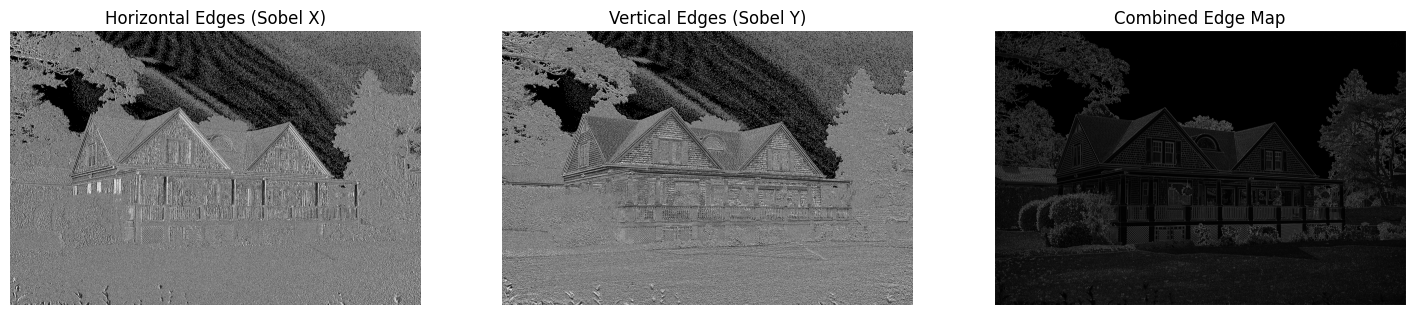

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def convolve_2d(image, kernel):
    """
    Perform 2D convolution without using built-in functions.

    Args:
        image (numpy.ndarray): Input grayscale image.
        kernel (numpy.ndarray): 2D filter (kernel).

    Returns:
        numpy.ndarray: Convolved output image.
    """
    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    # Compute padding sizes
    pad_h = kernel_height // 2
    pad_w = kernel_width // 2

    # Pad the image with zeros
    padded_image = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)

    # Initialize output array
    output = np.zeros((image_height, image_width))

    # Perform convolution
    for i in range(image_height):
        for j in range(image_width):
            region = padded_image[i:i+kernel_height, j:j+kernel_width]
            output[i, j] = np.sum(region * kernel)

    return output

# Load the grayscale image
house_image_path = "/content/house.jpg"  # Ensure correct image path
house_image = cv2.imread(house_image_path, cv2.IMREAD_GRAYSCALE)

# Check if the image is loaded correctly
if house_image is None:
    raise ValueError("House image not found. Please check the file path.")

# Define Sobel filters for edge detection
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])  # Horizontal edge detection

sobel_y = np.array([[-1, -2, -1],
                    [0, 0, 0],
                    [1, 2, 1]])  # Vertical edge detection

# Apply convolution to get horizontal and vertical edges
edges_x = convolve_2d(house_image, sobel_x)
edges_y = convolve_2d(house_image, sobel_y)

# Compute overall edge map by combining horizontal and vertical edges
edges_combined = np.sqrt(edges_x**2 + edges_y**2)
edges_combined = (edges_combined / edges_combined.max()) * 255  # Normalize to 0-255

# Convert to uint8 format
edges_x = edges_x.astype(np.uint8)
edges_y = edges_y.astype(np.uint8)
edges_combined = edges_combined.astype(np.uint8)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(edges_x, cmap='gray')
axes[0].set_title("Horizontal Edges (Sobel X)")
axes[0].axis("off")

axes[1].imshow(edges_y, cmap='gray')
axes[1].set_title("Vertical Edges (Sobel Y)")
axes[1].axis("off")

axes[2].imshow(edges_combined, cmap='gray')
axes[2].set_title("Combined Edge Map")
axes[2].axis("off")

plt.show()


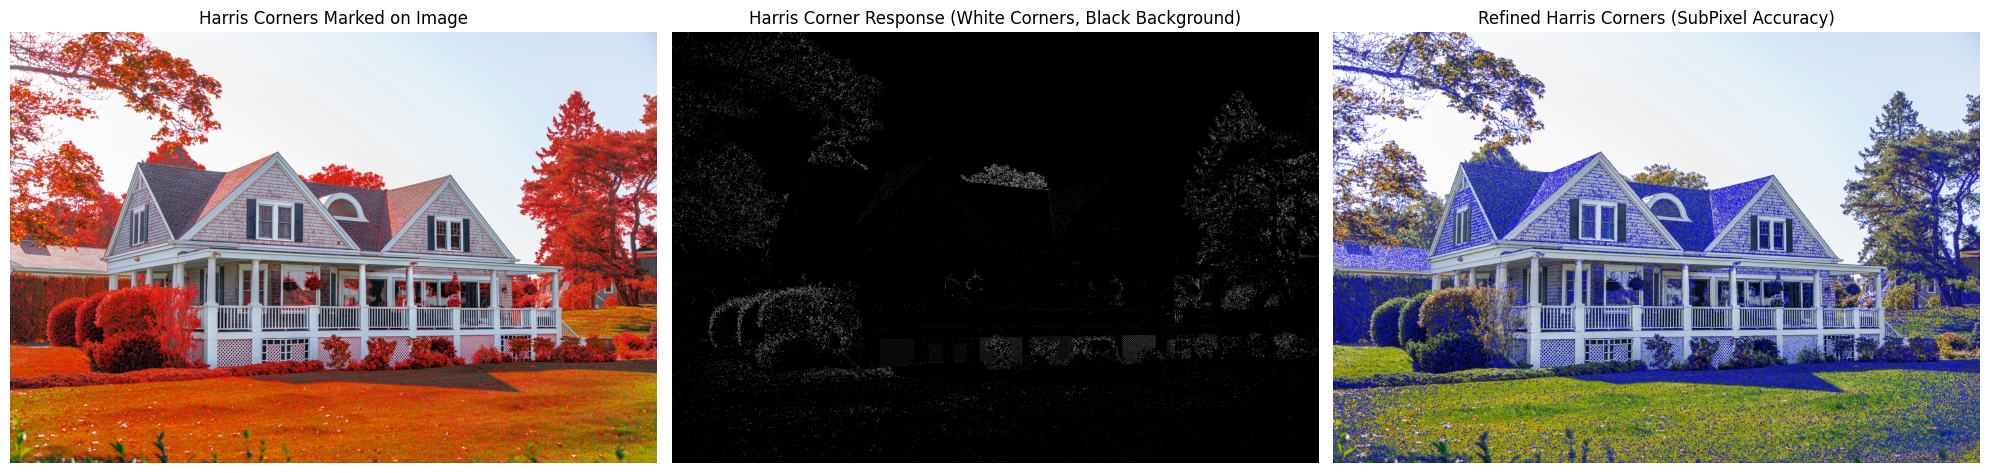

In [50]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1) Load and check the image
house_image_path = "/content/house.jpg"
img_original = cv2.imread(house_image_path)
if img_original is None:
    raise ValueError("House image not found. Please check the file path.")

# 2) Convert to grayscale (float32) and blur
gray = cv2.cvtColor(img_original, cv2.COLOR_BGR2GRAY)
gray = np.float32(gray)
gray_blurred = cv2.GaussianBlur(gray, (3, 3), 0)

# 3) Harris corner detection
dst = cv2.cornerHarris(gray_blurred, blockSize=2, ksize=3, k=0.04)

# 4) Create Harris corners image (red corners)
threshold_val = 0.00001 * dst.max()
img_corners = img_original.copy()
img_corners[dst > threshold_val] = [0, 0, 255]  # Red for corners

# 5) Create normalized response image (white corners, black background)
dst_norm = np.zeros_like(dst)
cv2.normalize(dst, dst_norm, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
dst_norm = dst_norm.astype(np.uint8)

# Create a black image
dst_norm_final = np.zeros_like(dst_norm)

# Set corner pixels to white
dst_norm_final[dst_norm > 100] = 255  # Strong corners in white, background black

# 6) Subpixel refinement
mask = (dst > threshold_val).astype(np.uint8) * 255
ret, labels, stats, centroids = cv2.connectedComponentsWithStats(mask)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.001)
corners_refined = cv2.cornerSubPix(gray_blurred, np.float32(centroids),
                                    (5, 5), (-1, -1), criteria)

# Create image with refined corners in blue
img_refined = img_original.copy()
for x, y in corners_refined:
    if 0 <= x < img_refined.shape[1] and 0 <= y < img_refined.shape[0]:
        cv2.circle(img_refined, (int(x), int(y)), 3, (255, 0, 0), -1)  # Blue circles

# 7) Display results side-by-side
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

# Left image: Harris corners in red
ax1.imshow(cv2.cvtColor(img_corners, cv2.COLOR_BGR2RGB))
ax1.set_title("Harris Corners Marked on Image")
ax1.axis("off")

# Middle image: Normalized response in black with white corners
ax2.imshow(dst_norm_final, cmap='gray')
ax2.set_title("Harris Corner Response (White Corners, Black Background)")
ax2.axis("off")

# Right image: Subpixel refined corners in blue
ax3.imshow(cv2.cvtColor(img_refined, cv2.COLOR_BGR2RGB))
ax3.set_title("Refined Harris Corners (SubPixel Accuracy)")
ax3.axis("off")

plt.tight_layout()
plt.show()


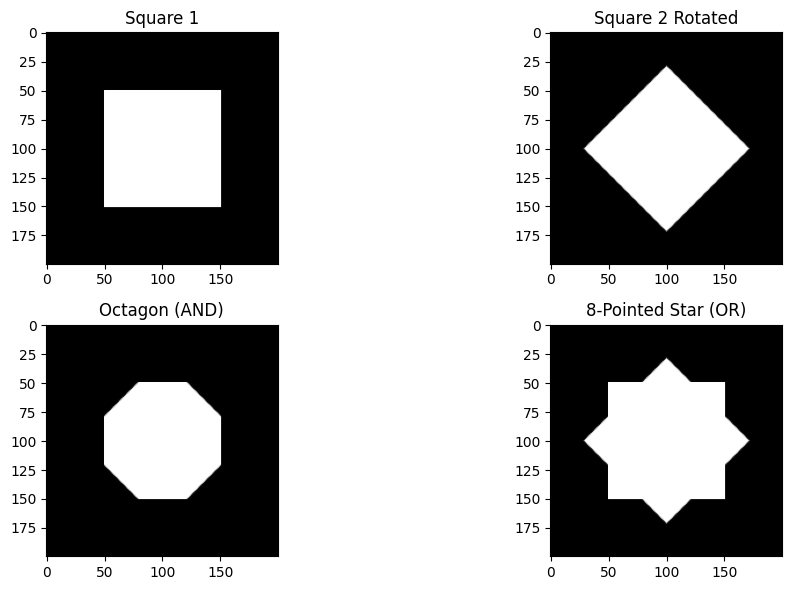

True

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create binary square images
size = 200
square1 = np.zeros((size, size), dtype=np.uint8)
square2 = np.zeros((size, size), dtype=np.uint8)

cv2.rectangle(square1, (50, 50), (150, 150), 255, -1)
cv2.rectangle(square2, (50, 50), (150, 150), 255, -1)

# Rotate square2 by 45 degrees
center = (size // 2, size // 2)
rotation_matrix = cv2.getRotationMatrix2D(center, 45, 1.0)
square2_rotated = cv2.warpAffine(square2, rotation_matrix, (size, size), borderValue=0)

# Perform bitwise operations
bitwise_or = cv2.bitwise_and(square1, square2_rotated)  # Union of squares (Octagon-like shape)
bitwise_xor = cv2.bitwise_or(square1, square2_rotated)  # XOR to create 8-pointed star

# Display results
plt.figure(figsize=(12, 6))  # Adjust figure size for better layout

plt.subplot(2, 2, 1)
plt.imshow(square1, cmap='gray')
plt.title('Square 1')

plt.subplot(2, 2, 2)
plt.imshow(square2_rotated, cmap='gray')
plt.title('Square 2 Rotated')

plt.subplot(2, 2, 3)
plt.imshow(bitwise_or, cmap='gray')
plt.title('Octagon (AND)')

plt.subplot(2, 2, 4)
plt.imshow(bitwise_xor, cmap='gray')
plt.title('8-Pointed Star (OR)')

plt.tight_layout() # Improves subplot spacing
plt.show()

# Save output images
cv2.imwrite('square1.png', square1)
cv2.imwrite('square2_rotated.png', square2_rotated)
cv2.imwrite('octagon.png', bitwise_or)
cv2.imwrite('8_pointed_star.png', bitwise_xor)